# 00. Import Library

In [1]:
import pickle
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# 01. Data preparation

Same CIFAR-10 files as Assignment 04, read from `../Assignment04/cifar-10-batches-py` (not copied again).

In [2]:
BASE = '../Assignment04/cifar-10-batches-py'   # same data as Assignment 04


def unpickle(file):   # loader given on the CIFAR-10 website
    with open(file, 'rb') as f:
        return pickle.load(f, encoding='bytes')


# train : data_batch_1 ~ 5 (50,000 images), test : test_batch (10,000 images)
train_batches = [unpickle(f'{BASE}/data_batch_{i}') for i in range(1, 6)]
X_train = np.concatenate([b[b'data'] for b in train_batches]).astype(np.float32)
y_train = np.concatenate([b[b'labels'] for b in train_batches])

test_batch = unpickle(f'{BASE}/test_batch')
X_test = np.array(test_batch[b'data']).astype(np.float32)
y_test = np.array(test_batch[b'labels'])

CLASSES = [c.decode() for c in unpickle(f'{BASE}/batches.meta')[b'label_names']]

print('train :', X_train.shape, y_train.shape)
print('test  :', X_test.shape, y_test.shape)
print('classes :', CLASSES)

train : (50000, 3072) (50000,)
test  : (10000, 3072) (10000,)
classes : ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


Pixels are scaled to [0, 1] and the mean train image is subtracted, so every pixel is centered at 0
and one learning rate fits all 3072 weights of a class.

In [3]:
mean_image = X_train.mean(axis=0) / 255
X_train = X_train / 255 - mean_image
X_test = X_test / 255 - mean_image

print(f'pixel range after preprocessing : {X_train.min():.2f} ~ {X_train.max():.2f}')

pixel range after preprocessing : -0.55 ~ 0.61


# 02. Linear classifier

$f(x, W) = Wx + b$ : the image $x$ is stretched to a 3072 x 1 column, $W$ is 10 x 3072 (one row per class) and $b$ is 10 x 1,
so the output is 10 class scores. The class with the highest score is the prediction.

In code the images are the rows of `X` (N x 3072), so N images are scored at once with `X @ W.T + b` (N x 10).

In [4]:
def predict_scores(X, W, b):
    return X @ W.T + b   # (N, 3072) x (3072, 10) + (10,) -> (N, 10)


rng = np.random.default_rng(0)
W = 0.0001 * rng.standard_normal((10, 3072))   # small random weights
b = np.zeros(10)

scores = predict_scores(X_train[:1], W, b)
print('W :', W.shape, ', b :', b.shape, ', scores of 1 image :', scores.shape)
print('parameters :', W.size + b.size, f'(KNN keeps all {X_train.size:,} train pixel values)')

W : (10, 3072) , b : (10,) , scores of 1 image : (1, 10)
parameters : 30730 (KNN keeps all 153,600,000 train pixel values)


# 03_1. SVM (hinge) loss

$L_i = \sum_{j \neq y_i} \max(0, s_j - s_{y_i} + 1)$, $\quad L = \frac{1}{N} \sum_i L_i$

$s_j$ : score of a wrong class, $s_{y_i}$ : score of the correct class.
A wrong class adds loss unless the correct class beats it by at least the margin 1.

Checked with the example of the lecture (3 images, classes cat / car / frog).

In [5]:
def svm_loss(scores, y):   # L_i of each image
    n = len(y)
    correct = scores[np.arange(n), y][:, None]      # s_y of each image
    margins = np.maximum(0, scores - correct + 1)    # max(0, s_j - s_y + 1)
    margins[np.arange(n), y] = 0                     # j = y is not counted
    return margins.sum(axis=1)


# lecture example : one row per image, columns = scores of cat, car, frog
toy_scores = np.array([[3.2, 5.1, -1.7],    # image 1, true class cat
                       [1.3, 4.9, 2.0],     # image 2, true class car
                       [2.2, 2.5, -3.1]])   # image 3, true class frog
toy_y = np.array([0, 1, 2])

toy_svm = svm_loss(toy_scores, toy_y)
print('L_i :', toy_svm.round(2))
print('L   :', toy_svm.mean().round(2))

L_i : [ 2.9  0.  12.9]
L   : 5.27


# 03_2. Softmax function

$P(Y = k \mid X = x_i) = \frac{e^{s_k}}{\sum_j e^{s_j}}$

The raw scores (logits) are unbounded. `exp` makes them positive and dividing by their sum makes them add up to 1, so they can be read as probabilities.
The largest score is subtracted before `exp` : the result is the same, but `exp` of a large score cannot overflow.

In [6]:
def softmax(scores):
    e = np.exp(scores - scores.max(axis=1, keepdims=True))   # minus the max : same result, no overflow
    return e / e.sum(axis=1, keepdims=True)


print('image 1 scores :', toy_scores[0])
print('exp            :', np.exp(toy_scores[0]).round(2))
print('normalize      :', softmax(toy_scores[:1])[0].round(2))

image 1 scores : [ 3.2  5.1 -1.7]
exp            : [ 24.53 164.02   0.18]
normalize      : [0.13 0.87 0.  ]


# 03_3. Softmax (cross-entropy) loss

$L_i = -\log P(Y = y_i \mid X = x_i)$

The loss is 0 only when the correct class gets probability 1, and grows without limit as that probability goes to 0.

In [7]:
def softmax_loss(scores, y):   # L_i of each image
    return -np.log(softmax(scores)[np.arange(len(y)), y])


toy_softmax = softmax_loss(toy_scores, toy_y)
pd.DataFrame({'P(correct)': softmax(toy_scores)[np.arange(3), toy_y],
              'SVM L_i': toy_svm,
              'Softmax L_i': toy_softmax},
             index=['image 1 (cat)', 'image 2 (car)', 'image 3 (frog)']).round(4)

,P(correct),SVM L_i,Softmax L_i
image 1 (cat),0.1300,2.9,2.0404
image 2 (car),0.9239,0.0,0.0791
image 3 (frog),0.0021,12.9,6.1565


Image 2 is correct with a margin larger than 1, so its SVM loss is already 0, but its softmax loss is not.
Raising the car score of image 2 shows the difference : SVM stops at 0 once the margin is met, softmax keeps going down.

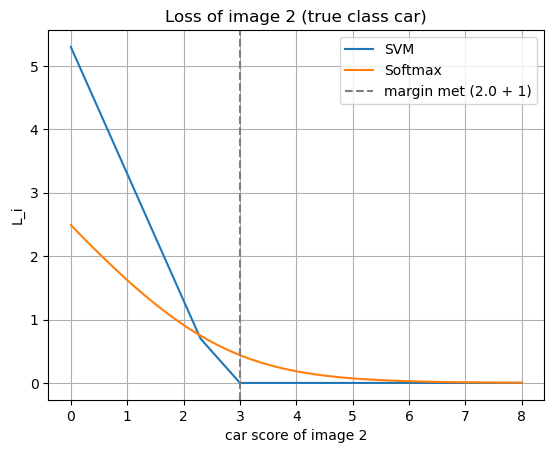

In [8]:
car_scores = np.linspace(0, 8, 81)
svm_curve, softmax_curve = [], []
for s in car_scores:
    scores = np.array([[1.3, s, 2.0]])   # image 2 with a different car score
    svm_curve.append(svm_loss(scores, [1])[0])
    softmax_curve.append(softmax_loss(scores, [1])[0])

plt.plot(car_scores, svm_curve, label='SVM')
plt.plot(car_scores, softmax_curve, label='Softmax')
plt.axvline(3.0, color='gray', linestyle='--', label='margin met (2.0 + 1)')
plt.xlabel('car score of image 2')
plt.ylabel('L_i')
plt.title('Loss of image 2 (true class car)')
plt.grid(True)
plt.legend()
plt.show()

# 03_4. Loss with random W

With small random $W$ all 10 scores are close to 0, so the expected loss is known :

- SVM : each of the 9 wrong classes gives $\max(0, 0 - 0 + 1) = 1$ $\rightarrow$ $L \approx 9$
- Softmax : every class gets probability $\frac{1}{10}$ $\rightarrow$ $L \approx -\log \frac{1}{10} = \log 10 \approx 2.303$

In [9]:
scores = predict_scores(X_train, W, b)
print(f'SVM loss     : {svm_loss(scores, y_train).mean():.4f} (expected 9)')
print(f'Softmax loss : {softmax_loss(scores, y_train).mean():.4f} (expected log 10 = {np.log(10):.4f})')

SVM loss     : 8.9999 (expected 9)
Softmax loss : 2.3026 (expected log 10 = 2.3026)


# 04. Training with gradient descent

The loss says how bad $W$ is. Gradient descent moves $W$ a small step against the gradient : $W \leftarrow W - lr \cdot \frac{\partial L}{\partial W}$.

The gradient is taken with respect to the scores $s$ first, then $s = Wx + b$ gives
$\frac{\partial L}{\partial W} = \left(\frac{\partial L}{\partial s}\right)^T X$ and $\frac{\partial L}{\partial b} = \sum_i \frac{\partial L}{\partial s_i}$.

| Loss | $\frac{\partial L_i}{\partial s_j}$ (wrong class $j$) | $\frac{\partial L_i}{\partial s_{y_i}}$ (correct class) |
|---|---|---|
| SVM | 1 if $s_j - s_{y_i} + 1 > 0$, else 0 | $-$(number of wrong classes with $s_j - s_{y_i} + 1 > 0$) |
| Softmax | $P_j$ | $P_{y_i} - 1$ |

Mini-batch gradient descent : 200 random images per step, 10 epochs (passes over the train set).

In [10]:
def svm_grad(scores, y):   # dL/ds of the mean loss
    n = len(y)
    ds = (scores - scores[np.arange(n), y][:, None] + 1 > 0).astype(float)   # 1 where the margin is not met
    ds[np.arange(n), y] = 0
    ds[np.arange(n), y] = -ds.sum(axis=1)
    return ds / n


def softmax_grad(scores, y):   # dL/ds of the mean loss
    ds = softmax(scores)
    ds[np.arange(len(y)), y] -= 1   # P - 1 for the correct class
    return ds / len(y)


LOSSES = {'SVM': (svm_loss, svm_grad), 'Softmax': (softmax_loss, softmax_grad)}


def train(X, y, loss, lr, epochs=10, batch_size=200, seed=0):
    loss_fn, grad_fn = LOSSES[loss]
    rng = np.random.default_rng(seed)
    W = 0.0001 * rng.standard_normal((10, X.shape[1]))
    b = np.zeros(10)
    history = []   # mean loss of each epoch
    for epoch in range(epochs):
        order = rng.permutation(len(X))
        losses = []
        for start in range(0, len(X), batch_size):
            i = order[start:start + batch_size]
            scores = predict_scores(X[i], W, b)
            losses.append(loss_fn(scores, y[i]).mean())
            ds = grad_fn(scores, y[i])
            W -= lr * ds.T @ X[i]
            b -= lr * ds.sum(axis=0)
        history.append(np.mean(losses))
    return W, b, history

# 04_1. 5-fold cross-validation

Same 5 folds as Assignment 04 (`StratifiedKFold`, `random_state=0`, train 40,000 / validation 10,000) and the same scores
(Accuracy, macro Precision / Recall / F1). Learning rate $lr$ = 0.0001, 0.001, 0.01, 0.1, 1 for both losses.

In [11]:
LR_LIST = [1e-4, 1e-3, 1e-2, 1e-1, 1]
SCORES = ['Accuracy', 'Precision', 'Recall', 'F1']


def get_scores(y_true, y_pred):
    return {'Accuracy': accuracy_score(y_true, y_pred),
            'Precision': precision_score(y_true, y_pred, average='macro', zero_division=0),
            'Recall': recall_score(y_true, y_pred, average='macro'),
            'F1': f1_score(y_true, y_pred, average='macro')}


skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
folds = list(skf.split(X_train, y_train))

results = []
for loss in LOSSES:
    for lr in LR_LIST:
        start = time.time()
        for fold, (tr, val) in enumerate(folds, 1):
            W, b, _ = train(X_train[tr], y_train[tr], loss, lr)
            pred = predict_scores(X_train[val], W, b).argmax(axis=1)   # class with the highest score
            results.append({'loss': loss, 'lr': lr, 'fold': fold, **get_scores(y_train[val], pred)})
        print(f'{loss} lr={lr:g} done ({time.time() - start:.0f} s for 5 folds)')

cv = pd.DataFrame(results)

SVM lr=0.0001 done (30 s for 5 folds)


SVM lr=0.001 done (30 s for 5 folds)


SVM lr=0.01 done (30 s for 5 folds)


SVM lr=0.1 done (31 s for 5 folds)


SVM lr=1 done (32 s for 5 folds)


Softmax lr=0.0001 done (29 s for 5 folds)


Softmax lr=0.001 done (31 s for 5 folds)


Softmax lr=0.01 done (31 s for 5 folds)


Softmax lr=0.1 done (30 s for 5 folds)


Softmax lr=1 done (30 s for 5 folds)


# 04_2. Effect of learning rate

Mean and standard deviation over the 5 folds.

In [12]:
summary = cv.groupby(['loss', 'lr'])[SCORES].agg(['mean', 'std']).round(4)
summary

Accuracy         Precision          Recall              F1  \
                   mean     std      mean     std    mean     std    mean   
loss    lr                                                                  
SVM     0.0001   0.3373  0.0037    0.3396  0.0057  0.3373  0.0037  0.3169   
        0.0010   0.3796  0.0065    0.3789  0.0059  0.3796  0.0065  0.3750   
        0.0100   0.3944  0.0052    0.3935  0.0044  0.3944  0.0052  0.3924   
        0.1000   0.3466  0.0147    0.3596  0.0094  0.3466  0.0147  0.3430   
        1.0000   0.3034  0.0141    0.3321  0.0174  0.3034  0.0141  0.2955   
Softmax 0.0001   0.2662  0.0062    0.3045  0.0120  0.2662  0.0062  0.2190   
        0.0010   0.3418  0.0042    0.3434  0.0059  0.3418  0.0042  0.3190   
        0.0100   0.3940  0.0060    0.3883  0.0058  0.3940  0.0060  0.3875   
        0.1000   0.4076  0.0053    0.4041  0.0054  0.4076  0.0053  0.4037   
        1.0000   0.2923  0.0214    0.3304  0.0184  0.2923  0.0214  0.2850   

                        
                   std  
loss    lr              
SVM     0.0001  0.0044  
        0.0010  0.0064  
        0.0100  0.0049  
        0.1000  0.0142  
        1.0000  0.0162  
Softmax 0.0001  0.0058  
        0.0010  0.0041  
        0.0100  0.0060  
        0.1000  0.0059  
        1.0000  0.0233

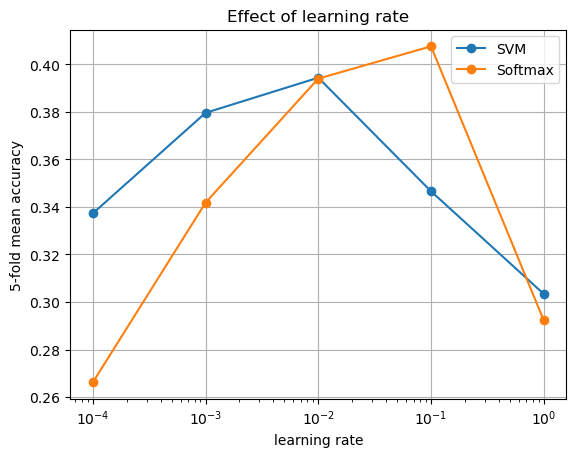

In [13]:
for loss in LOSSES:
    plt.plot(LR_LIST, summary.loc[loss][('Accuracy', 'mean')], marker='o', label=loss)
plt.xscale('log')
plt.xlabel('learning rate')
plt.ylabel('5-fold mean accuracy')
plt.title('Effect of learning rate')
plt.grid(True)
plt.legend()
plt.show()

The best $lr$ of each loss is the one with the highest 5-fold mean accuracy (the test set is not used).

In [14]:
best_lr = {}
for loss in LOSSES:
    acc = summary.loc[loss][('Accuracy', 'mean')]
    best_lr[loss] = acc.idxmax()
    print(f'{loss} : best lr = {best_lr[loss]:g}, 5-fold accuracy = {acc.max():.4f}')

best_loss = max(LOSSES, key=lambda loss: summary.loc[(loss, best_lr[loss]), ('Accuracy', 'mean')])
print('\nBest model (5-fold) :', best_loss, ', lr =', best_lr[best_loss])

SVM : best lr = 0.01, 5-fold accuracy = 0.3944
Softmax : best lr = 0.1, 5-fold accuracy = 0.4076

Best model (5-fold) : Softmax , lr = 0.1


# 05_1. Final evaluation on the test set

Each loss with its best $lr$ from 04_2 : train on all 50,000 images, test on the 10,000 images of `test_batch`.

In [15]:
test_results, test_pred, models = [], {}, {}
for loss in LOSSES:
    start = time.time()
    W, b, history = train(X_train, y_train, loss, best_lr[loss])
    train_time = time.time() - start

    start = time.time()
    test_pred[loss] = predict_scores(X_test, W, b).argmax(axis=1)
    test_time = time.time() - start

    models[loss] = (W, b, history)
    test_results.append({'loss': loss, 'lr': best_lr[loss], **get_scores(y_test, test_pred[loss]),
                         'train time (s)': train_time, 'test time (s)': test_time})

pd.DataFrame(test_results).round(4)

,loss,lr,Accuracy,Precision,Recall,F1,train time (s),test time (s)
0,SVM,0.01,0.3971,0.3986,0.3971,0.3958,7.3087,0.0587
1,Softmax,0.10,0.4107,0.4112,0.4107,0.4078,7.4726,0.0514


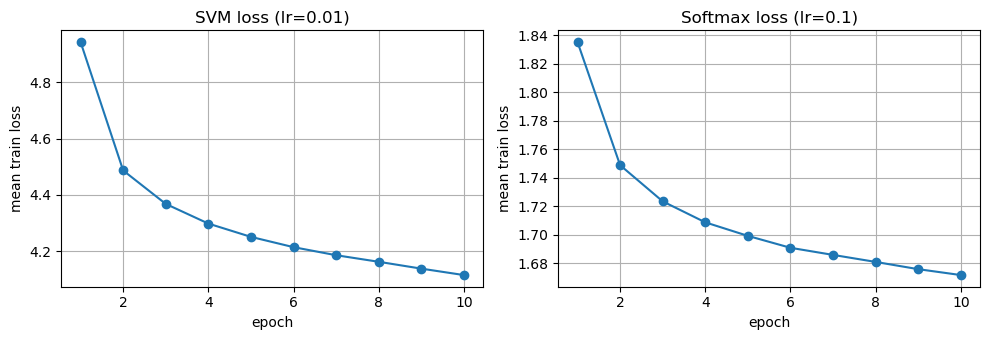

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, loss in zip(axes, LOSSES):
    history = models[loss][2]
    ax.plot(range(1, len(history) + 1), history, marker='o')
    ax.set_title(f'{loss} loss (lr={best_lr[loss]:g})')
    ax.set_xlabel('epoch')
    ax.set_ylabel('mean train loss')
    ax.grid(True)
plt.tight_layout()
plt.show()

# 05_2. Per-class results

In [17]:
pred = test_pred[best_loss]
print(f'[{best_loss}, lr={best_lr[best_loss]:g}] test set\n')
print(classification_report(y_test, pred, target_names=CLASSES, digits=4))

[Softmax, lr=0.1] test set

              precision    recall  f1-score   support

    airplane     0.4219    0.6050    0.4971      1000
  automobile     0.4796    0.4700    0.4747      1000
        bird     0.2963    0.3040    0.3001      1000
         cat     0.3044    0.3050    0.3047      1000
        deer     0.3609    0.2840    0.3179      1000
         dog     0.3664    0.3030    0.3317      1000
        frog     0.4286    0.4770    0.4515      1000
       horse     0.4848    0.4320    0.4569      1000
        ship     0.5346    0.4480    0.4875      1000
       truck     0.4347    0.4790    0.4558      1000

    accuracy                         0.4107     10000
   macro avg     0.4112    0.4107    0.4078     10000
weighted avg     0.4112    0.4107    0.4078     10000



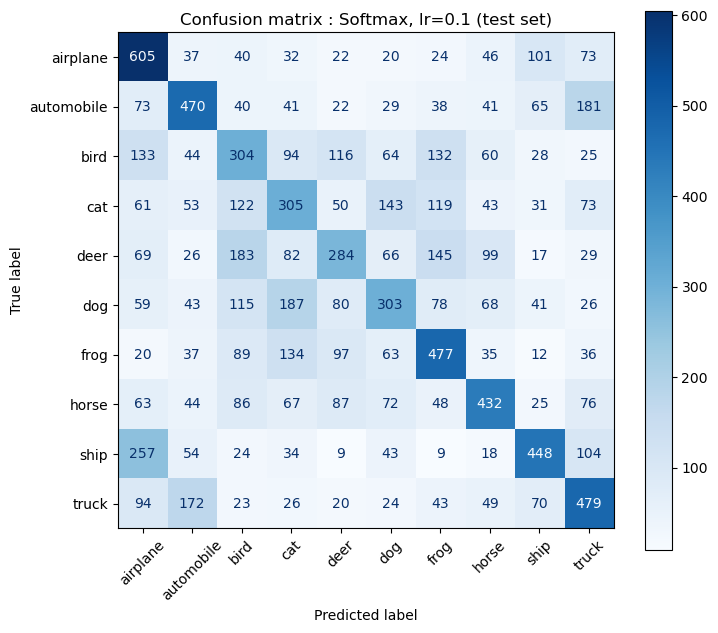

In [18]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=CLASSES, xticks_rotation=45, cmap='Blues', ax=ax)
plt.title(f'Confusion matrix : {best_loss}, lr={best_lr[best_loss]:g} (test set)')
plt.show()

# 05_3. Learned weights as templates

Each row of $W$ (3072 values) reshaped back to 32 x 32 x 3 : one template per class (visual viewpoint of the lecture).
The score of a class is the dot product of the image with its template, so a bright part of the template
means "this color at this position raises the score". Each template is rescaled to [0, 1] for display.

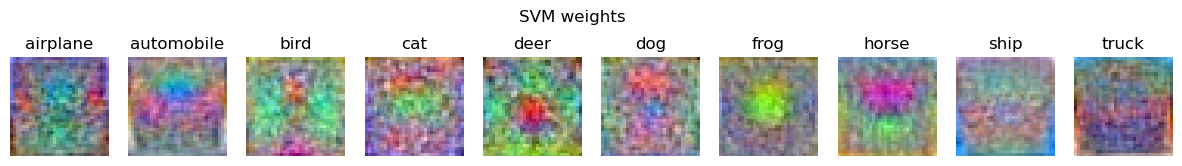

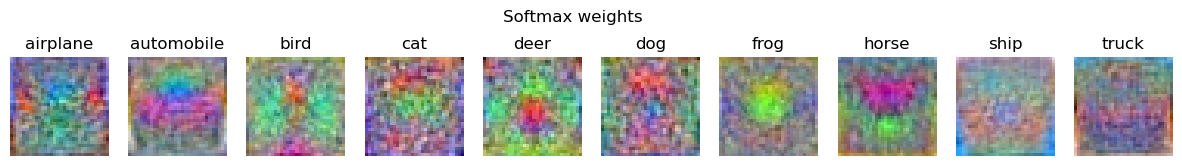

In [19]:
for loss in LOSSES:
    W = models[loss][0]
    plt.figure(figsize=(15, 2))
    for c in range(10):
        template = W[c].reshape(3, 32, 32).transpose(1, 2, 0)
        plt.subplot(1, 10, c + 1)
        plt.imshow((template - template.min()) / (template.max() - template.min()))
        plt.title(CLASSES[c])
        plt.axis('off')
    plt.suptitle(f'{loss} weights')
    plt.show()

# 06. Comparison & explanation

| Model | Best setting (5-fold) | 5-fold Accuracy | Test Accuracy | Test Precision | Test Recall | Test F1 | Test time |
|---|---|---|---|---|---|---|---|
| **Softmax** | **lr = 0.1** | **0.4076 ± 0.0053** | **0.4107** | **0.4112** | **0.4107** | **0.4078** | **0.05 s** |
| SVM | lr = 0.01 | 0.3944 ± 0.0052 | 0.3971 | 0.3986 | 0.3971 | 0.3958 | 0.06 s |
| KNN L1 (Assignment 04) | k = 5 | 0.3791 ± 0.0030 | 0.3921 | 0.4560 | 0.3921 | 0.3890 | 302 s |

- **Best model : Softmax, lr=0.1**, selected by 5-fold CV only. Test accuracy is 41.1% (chance level 10%), close to the 5-fold 40.8%.
- **Loss functions** : the code gives the same values as the lecture example (SVM $L$ = 5.27, softmax 0.13 / 0.87 / 0.00). SVM loss is exactly 0 once the correct class wins by the margin 1 (image 2), while softmax loss is never 0 and keeps pushing the correct score up (03_3). With random $W$ both start at the expected values, 9 and $\log 10$ (03_4).
- **Effect of learning rate** : 0.0001 moves $W$ too little in 10 epochs, and 1 overshoots (lower accuracy, larger std over the folds). SVM needs a 10x smaller $lr$ than softmax : its gradient for the correct class is $-$(number of classes inside the margin), up to $-9$ per image, while every softmax gradient ($P - 1$ or $P$) stays between $-1$ and $1$.
- **SVM vs Softmax** : Softmax > SVM in all 5 folds, by 1.1 ~ 1.7 points. Both learn almost the same model : they give the same prediction for 85.1% of the test images, and their templates in 05_3 look alike.
- **vs KNN** : the accuracy is about the same (41.1% / 39.7% vs 39.2%), but the linear classifier keeps only 30,730 parameters instead of all 153,600,000 train pixel values, and classifies the 10,000 test images in 0.05 s instead of 302 s (training takes about 7 s). KNN has a higher precision (0.4560) because it rarely predicts some classes, while the linear classifier predicts every class about equally often (precision ≈ recall).
- **Limit** : one template per class (05_3) is an average of all images of the class, so it mostly encodes color and position (blue for airplane / ship, green in the middle for frog / deer). The most common errors are classes with similar colors and layouts : ship -> airplane 257, dog -> cat 187, deer -> bird 183, automobile -> truck 181, truck -> automobile 172. No regularization is used, so the templates are noisy.